# Quadratic assignment

A company rents one floor with twelve rooms and has twelve departments to put in them. People walk
between departments all day: engineers to the test lab, sales to marketing, finance to legal. The
walking depends on which rooms the two departments get, so no room can be chosen on its own. The
question is **which department goes in which room, so that people walk as little as possible**.

That is a quadratic assignment problem: the cost of a choice depends on another choice. Assignment
problems without that coupling are far easier.

In this notebook you will:

1. describe the floor and the walking as Python objects,
2. solve it and draw the floor before and after, with the walking drawn in,
3. check the result yourself, and prove it by listing every allowed layout,
4. drop a rule and see what it was costing,
5. put a price on moving and see how much of the floor is worth moving,
6. restart from the current layout with a department pinned.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyArrowPatch, Patch, Rectangle

from optimaru import quadratic_assignment as qa
from optimaru.quadratic_assignment import constraints as rules
from optimaru.quadratic_assignment.models import QuadraticAssignmentProblemModel

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the floor

One pydantic model holds everything, and `assignment` is what the solver fills in.

| Field of `QuadraticAssignmentProblemModel` | What it holds |
| --- | --- |
| `facilities`, `locations` | the department names and the room names, the same number of each |
| `flows` | a square matrix: trips per day from one department to another |
| `distances` | a square matrix: metres from one room to another |
| `fixed_assignments` | `{location: facility}` pairs that must hold |
| `forbidden_assignments` | facility and location pairs that must not happen |
| `facility_demands`, `location_capacities` | how much each facility needs and each location offers |
| `assignment_costs` | an optional matrix: the direct cost of each facility in each location |

The cost of a layout sums flow times distance over every ordered pair of departments, so a trip from
Sales to Marketing and a trip back are two separate entries. Both matrices are integers.

Here is a fictional floor: three rows of four rooms, 9 metres wide and 7 deep, with distance measured
along the corridors. The rooms in row A seat 14, row B seats 10 and row C seats 6. Reception stays
at the entrance in room C2.

In [2]:
HEADCOUNT = {
    "Engineering": 13, "Sales": 12, "Support": 11, "Marketing": 9, "QA": 9, "Finance": 8,
    "Design": 6, "HR": 5, "Legal": 4, "IT": 5, "Reception": 3, "Print room": 2,
}
GROUPS = {
    "Product": ["Engineering", "QA", "Design"],
    "Commercial": ["Sales", "Marketing", "Support"],
    "Back office": ["Finance", "Legal", "HR"],
    "Services": ["IT", "Reception", "Print room"],
}
TRIPS = [
    ("Engineering", "QA", 28), ("Sales", "Marketing", 22), ("Engineering", "Design", 18), ("Finance", "Legal", 16),
    ("Support", "QA", 14), ("Sales", "Support", 12), ("IT", "Engineering", 12), ("Print room", "Marketing", 11),
    ("Reception", "Sales", 10), ("Design", "Marketing", 10), ("HR", "Finance", 9), ("Support", "Engineering", 9),
    ("Reception", "HR", 8), ("Print room", "Finance", 7), ("Legal", "Sales", 6), ("IT", "Support", 6),
]

DEPARTMENTS = list(HEADCOUNT)
ROOMS = [f"{row}{column}" for row in "ABC" for column in range(1, 5)]
ROOM_XY = {room: ((int(room[1]) - 1) * 9, (2 - "ABC".index(room[0])) * 7) for room in ROOMS}
SEATS = {room: {"A": 14, "B": 10, "C": 6}[room[0]] for room in ROOMS}

TODAY = dict(zip(ROOMS, [
    "Support", "Finance", "Engineering", "Sales",
    "Marketing", "Design", "Legal", "QA",
    "IT", "Reception", "HR", "Print room",
]))

flows = np.zeros((len(DEPARTMENTS), len(DEPARTMENTS)), dtype=int)
for first, second, trips in TRIPS:
    i, j = DEPARTMENTS.index(first), DEPARTMENTS.index(second)
    flows[i, j] = flows[j, i] = trips

distances = np.array([
    [abs(ROOM_XY[a][0] - ROOM_XY[b][0]) + abs(ROOM_XY[a][1] - ROOM_XY[b][1]) for b in ROOMS] for a in ROOMS
])


def make_problem(moving_cost_per_seat=None, **fields):
    """A fresh, unsolved floor. The solver works in place, so each experiment gets its own."""
    moves = None
    if moving_cost_per_seat is not None:  # staying put is free, moving costs per seat
        moves = [
            [0 if TODAY[room] == department else HEADCOUNT[department] * moving_cost_per_seat for room in ROOMS]
            for department in DEPARTMENTS
        ]
    return QuadraticAssignmentProblemModel(
        facilities=DEPARTMENTS,
        locations=ROOMS,
        flows=flows.tolist(),
        distances=distances.tolist(),
        facility_demands=HEADCOUNT,
        location_capacities=SEATS,
        fixed_assignments={"C2": "Reception"},
        assignment_costs=moves,
        **fields,
    )


def walking(problem):
    """Flow times distance: the same number the score uses, without any moving cost."""
    return qa.constraint_costs(problem)["minimize_flow_distance"][0]


current = make_problem(assignment=TODAY)
today_score = qa.calculate_score(current)
print(f"{len(DEPARTMENTS)} departments, {len(ROOMS)} rooms, {sum(HEADCOUNT.values())} people, "
      f"{sum(SEATS.values())} seats")
print("today's layout:", today_score)

12 departments, 12 rooms, 87 people, 120 seats
today's layout: Score(hard=0, soft=-9106.0)


The flow matrix is the input worth looking at: it shows who needs to be near whom.

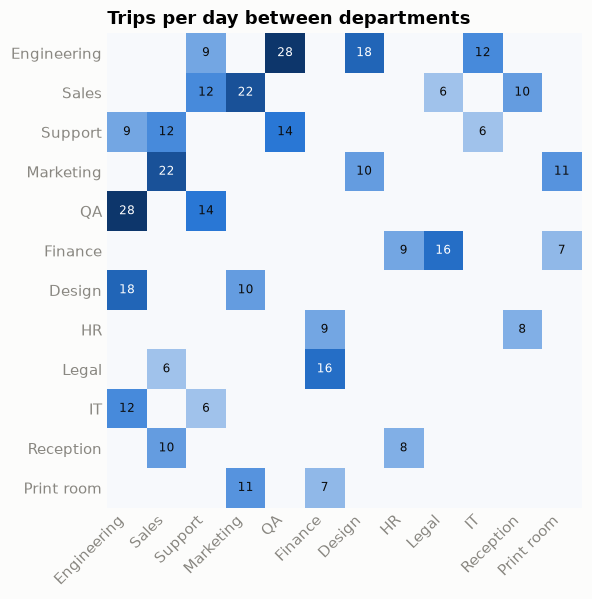

In [3]:
blues = LinearSegmentedColormap.from_list("blue", ["#f7f9fc", "#2a78d6", "#0d366b"])

fig, ax = plt.subplots(figsize=(6.8, 5.6))
ax.imshow(flows, cmap=blues, vmin=0)
for (row, column), trips in np.ndenumerate(flows):
    if trips:
        ax.text(column, row, str(trips), ha="center", va="center", fontsize=8,
                color="white" if trips > flows.max() / 2 else "#0b0b0b")
ax.set_xticks(range(len(DEPARTMENTS)), DEPARTMENTS, rotation=45, ha="right")
ax.set_yticks(range(len(DEPARTMENTS)), DEPARTMENTS)
ax.set_title("Trips per day between departments")
ax.tick_params(length=0)
ax.spines[["left", "bottom"]].set_visible(False)
plt.show()

## 2. Solve it

`qa.solve` fills in `assignment`, a dict from room to department, plus `total_cost`, `score_hard` and
`score_soft`, and returns the score. This use case has no compiled core: it runs a simulated
annealing written in Python that swaps two departments per step, starting from the order of the
lists. The search stops at `time_limit_seconds` or after `SolverConfig.max_iterations` steps, 50,000
by default, whichever comes first.

The score has two levels, compared in order:

- **hard**: minus the broken fixed and forbidden pairs and the seats short, where `0` means allowed
- **soft**: minus the sum of the walking cost and any direct assignment cost

In [4]:
problem = make_problem()
score = qa.solve(problem, time_limit_seconds=5, random_seed=42)

print("score    :", score)
print("walking  :", walking(problem), f"(today {walking(current)})")
print("moved    :", sum(problem.assignment[room] != TODAY[room] for room in ROOMS), "of", len(ROOMS), "rooms")

score    : (0, -4478.0)
walking  : 4478 (today 9106)
moved    : 9 of 12 rooms


### The floor before and after

Each box is a room, with its department and its seats in use. Each curve is a pair of departments
that walk to each other, and a thicker curve means more trips. Colors mark the department groups.
Short thick curves are what the search is after.

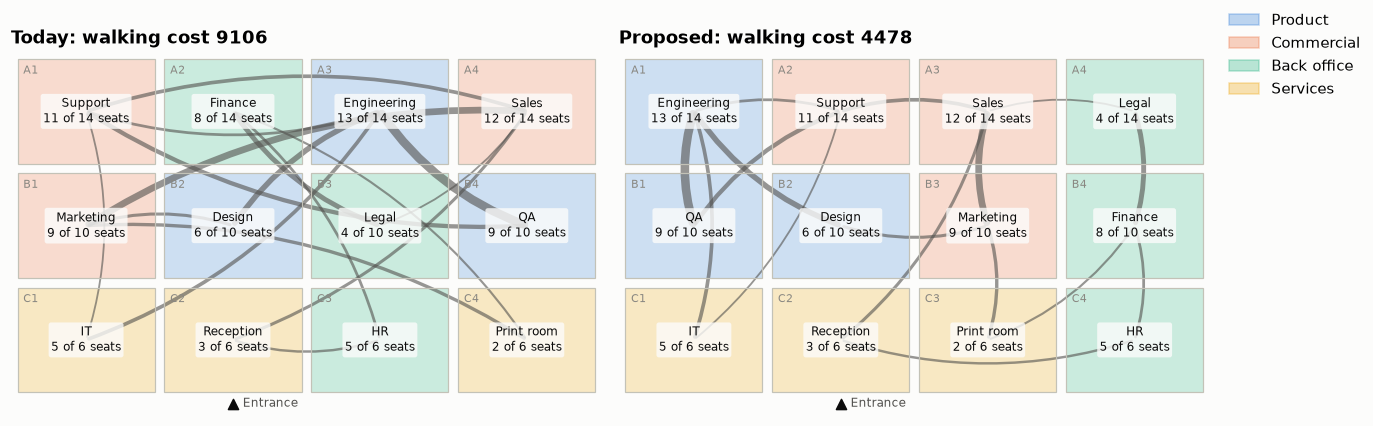

In [5]:
GROUP_OF = {department: group for group, members in GROUPS.items() for department in members}
GROUP_COLOR = dict(zip(GROUPS, COLORS))
ROOM_W, ROOM_H = 8.4, 6.4


def draw_floor(ax, assignment):
    room_of = {department: room for room, department in assignment.items()}
    for room, (x, y) in ROOM_XY.items():
        department = assignment[room]
        over = HEADCOUNT[department] > SEATS[room]
        ax.add_patch(Rectangle((x, y), ROOM_W, ROOM_H, facecolor=GROUP_COLOR[GROUP_OF[department]], alpha=0.22,
                               edgecolor="none", zorder=1))
        ax.add_patch(Rectangle((x, y), ROOM_W, ROOM_H, fill=False, zorder=3,
                               edgecolor=COLORS[7] if over else "#c3c2b7", linewidth=2.2 if over else 0.8))
        ax.text(x + 0.35, y + ROOM_H - 0.35, room, va="top", fontsize=7.5, color=MUTED, zorder=4)
        ax.text(x + ROOM_W / 2, y + ROOM_H / 2, f"{department}\n{HEADCOUNT[department]} of {SEATS[room]} seats",
                ha="center", va="center", fontsize=8, color="#0b0b0b", zorder=4,
                bbox={"boxstyle": "round,pad=0.2", "facecolor": "#fcfcfb", "edgecolor": "none", "alpha": 0.8})
    for first, second, trips in TRIPS:
        start, end = [
            (ROOM_XY[room_of[name]][0] + ROOM_W / 2, ROOM_XY[room_of[name]][1] + ROOM_H / 2)
            for name in (first, second)
        ]
        ax.add_patch(FancyArrowPatch(start, end, connectionstyle="arc3,rad=0.16", arrowstyle="-", color=INK,
                                     linewidth=trips / 5, alpha=0.6, zorder=2))
    entrance_x = ROOM_XY["C2"][0] + ROOM_W / 2
    ax.scatter(entrance_x, -0.7, marker="^", s=44, color="#0b0b0b", clip_on=False)
    ax.text(entrance_x + 0.6, -0.7, "Entrance", va="center", fontsize=8, color=INK)
    ax.set(xlim=(-0.4, 36), ylim=(-1.4, 20.8), aspect="equal")
    ax.axis("off")


group_legend = [Patch(color=color, alpha=0.3, label=group) for group, color in GROUP_COLOR.items()]

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.2), layout="constrained")
draw_floor(axes[0], TODAY)
draw_floor(axes[1], problem.assignment)
axes[0].set_title(f"Today: walking cost {walking(current)}", loc="left")
axes[1].set_title(f"Proposed: walking cost {walking(problem)}", loc="left")
fig.legend(handles=group_legend, loc="outside right upper")
plt.show()

## 3. Check the result yourself

The answer is a dict, so the rules can be checked with no solver code, and the walking cost is one
line of numpy.

With twelve rooms and these rules, a stronger check is possible. The seat limits and the fixed
Reception leave few allowed layouts, so the cell below lists every one of them and takes the
cheapest. That is a proof about this instance, and it only works because the instance is small: each
added room multiplies the list, which is why the solver exists.

In [6]:
order = [DEPARTMENTS.index(problem.assignment[room]) for room in ROOMS]
recomputed = int((flows[np.ix_(order, order)] * distances).sum())

print("each department once :", sorted(problem.assignment.values()) == sorted(DEPARTMENTS))
print("seats short          :", [
    room for room, department in problem.assignment.items() if HEADCOUNT[department] > SEATS[room]
])
print("Reception at C2      :", problem.assignment["C2"] == "Reception")
print("walking recomputed   :", recomputed, "matches" if recomputed == walking(problem) else "DIFFERS")


def allowed_layouts():
    """Every layout that fits the seats with Reception in C2, as rows of department numbers by room."""
    layout = [-1] * len(ROOMS)
    layout[ROOMS.index("C2")] = DEPARTMENTS.index("Reception")
    biggest_first = sorted((d for d in DEPARTMENTS if d != "Reception"), key=lambda d: -HEADCOUNT[d])

    def place(depth):
        if depth == len(biggest_first):
            yield layout.copy()
            return
        department = biggest_first[depth]
        for room_index, room in enumerate(ROOMS):
            if layout[room_index] < 0 and HEADCOUNT[department] <= SEATS[room]:
                layout[room_index] = DEPARTMENTS.index(department)
                yield from place(depth + 1)
                layout[room_index] = -1

    yield from place(0)


layouts = np.array(list(allowed_layouts()), dtype=np.int16)
costs = (flows[layouts[:, :, None], layouts[:, None, :]] * distances).sum(axis=(1, 2))

print(f"allowed layouts      : {len(layouts)}")
print(f"cheapest of them     : {costs.min()}")
if walking(problem) == costs.min():
    print("the solver's layout is proven optimal for these rules")
else:
    print(f"the solver's layout is {walking(problem) - costs.min()} above the optimum")

each department once : True
seats short          : []
Reception at C2      : True
walking recomputed   : 4478 matches
allowed layouts      : 172800
cheapest of them     : 4478
the solver's layout is proven optimal for these rules


## 4. Change the rules, not the solver

Every rule is a plugin. `list_constraints()` shows what ships with this use case, and the
`constraints` argument takes the list you want. Only listed constraints are scored. `weight` scales
a rule, `hard` moves it between levels, and `exponent` shapes large violations.

Seats shape this floor: the three largest departments only fit in row A. Dropping
`location_capacities` from the list shows what that limit costs in walking. A red outline marks a
room that cannot seat its department.

fixed_assignments
forbidden_assignments
location_capacities
minimize_assignment_cost
minimize_flow_distance


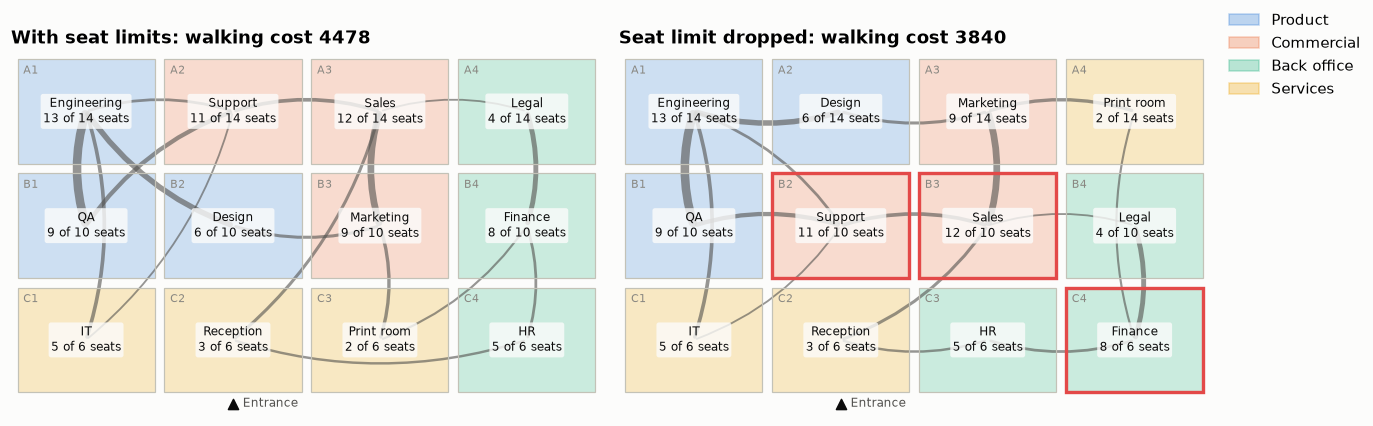

seat limit dropped: score (0, -3840.0), rooms that cannot seat their department: ['B2', 'B3', 'C4']


In [7]:
for name in qa.list_constraints():
    print(name)

no_seat_limit = make_problem()
no_limit_score = qa.solve(no_seat_limit, time_limit_seconds=5, random_seed=42, constraints=[
    rules.fixed_assignments,
    rules.forbidden_assignments,
    rules.minimize_assignment_cost,
    rules.minimize_flow_distance,
])

fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.2), layout="constrained")
draw_floor(axes[0], problem.assignment)
draw_floor(axes[1], no_seat_limit.assignment)
axes[0].set_title(f"With seat limits: walking cost {walking(problem)}", loc="left")
axes[1].set_title(f"Seat limit dropped: walking cost {walking(no_seat_limit)}", loc="left")
fig.legend(handles=group_legend, loc="outside right upper")
plt.show()

short = [room for room, name in no_seat_limit.assignment.items() if HEADCOUNT[name] > SEATS[room]]
print(f"seat limit dropped: score {no_limit_score}, rooms that cannot seat their department: {short}")

## 5. Is every move worth it?

A better layout means moving departments, and moving costs money. `assignment_costs` holds the direct
cost of each department in each room. Here staying costs nothing and moving costs 30 per seat.
`minimize_assignment_cost` scales that with `weight`, so one sweep over the weight traces the whole
trade-off between disruption and daily walking, without changing the data.

weight 0: 9 rooms change, walking 4478
weight 0.5: 7 rooms change, walking 4568
weight 1: 5 rooms change, walking 5162
weight 2: 5 rooms change, walking 5162
weight 4: 0 rooms change, walking 9106


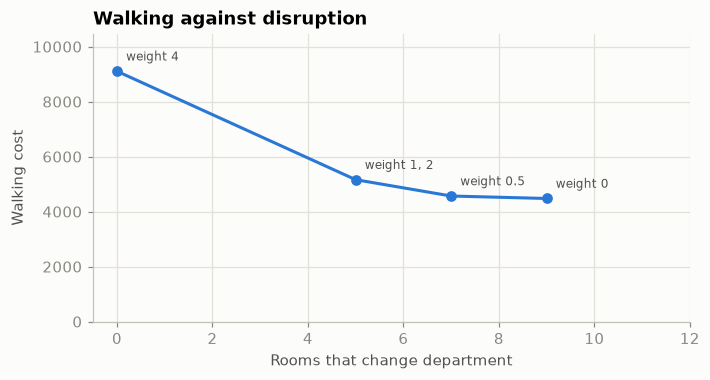

In [8]:
weights = [0, 0.5, 1, 2, 4]
points = {}
for weight in weights:
    candidate = make_problem(moving_cost_per_seat=30)
    candidate_score = qa.solve(candidate, time_limit_seconds=5, random_seed=42, constraints=[
        rules.fixed_assignments,
        rules.location_capacities,
        rules.minimize_flow_distance,
        rules.MinimizeAssignmentCost(weight=weight),
    ])
    assert candidate_score[0] == 0, f"no allowed layout found at weight {weight}"
    moved = sum(candidate.assignment[room] != TODAY[room] for room in ROOMS)
    points.setdefault((moved, walking(candidate)), []).append(weight)
    print(f"weight {weight}: {moved} rooms change, walking {walking(candidate)}")

fig, ax = plt.subplots(figsize=(7, 3.4))
ordered = sorted(points)
ax.plot(*zip(*ordered), color=COLORS[0], linewidth=2, marker="o", markersize=6)
for (moved, walked), used in points.items():
    ax.annotate("weight " + ", ".join(str(weight) for weight in used), (moved, walked), xytext=(6, 7),
                textcoords="offset points", color=INK, fontsize=8)
ax.set(title="Walking against disruption", xlabel="Rooms that change department", ylabel="Walking cost",
       ylim=(0, walking(current) * 1.15), xlim=(-0.5, len(ROOMS)))
ax.grid(True)
plt.show()

Two weights can land on the same layout: rooms come in whole departments, so the trade-off moves in
steps. Read the chart from the left: each point shows what the next group of moves saves in walking,
which is the number to weigh against the cost of moving.

`total_cost` on the model adds the direct assignment cost to the walking, which is why this notebook
reads the walking from `constraint_costs` instead.

## 6. Restart from an existing layout

`with_initial_solution` starts the search from a solved model, or a dict with an `assignment`, which
must place every department once. Without it the search starts from the order of the lists.

**Change `random_seed` between rounds.** A round that finds nothing new leaves the layout as it was,
so with the same seed the next round starts from the same layout with the same random numbers,
repeats the same steps and finds nothing again.

The rounds also set `temperature=100`. A short round at the default of 2.0 is close to pure descent:
a swap here changes the cost by tens or hundreds, so the round stops at the first layout no single
swap improves, and a new seed from there has no way out. The chart starts every run from today's
layout and spends 1,000 steps per round.

same seed 0: [4478, 4478, 4478, 4478, 4478, 4478, 4478, 4478]
same seed 1: [4908, 4908, 4908, 4908, 4908, 4908, 4908, 4908]
same seed 2: [4946, 4946, 4946, 4946, 4946, 4946, 4946, 4946]
same seed 3: [5122, 5122, 5122, 5122, 5122, 5122, 5122, 5122]
new seeds from 100: [4910, 4478, 4478, 4478, 4478, 4478, 4478, 4478]
new seeds from 200: [4892, 4892, 4892, 4892, 4786, 4478, 4478, 4478]
new seeds from 300: [4908, 4908, 4908, 4478, 4478, 4478, 4478, 4478]
new seeds from 400: [4908, 4908, 4908, 4908, 4908, 4908, 4908, 4908]


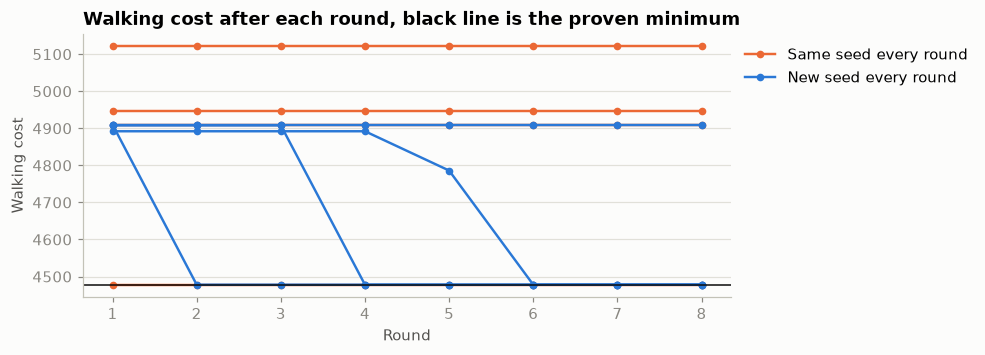

In [9]:
def run_rounds(seeds, steps=1000):
    """Walking cost after each short round, every round continuing from the previous layout."""
    plan, history = make_problem(assignment=TODAY), []
    for seed in seeds:
        warm = qa.with_initial_solution(make_problem(), plan)
        qa.solve(warm, config=qa.SolverConfig(temperature=100, max_iterations=steps, random_seed=seed))
        plan = warm
        history.append(walking(plan))
    return history


ROUNDS = 8
rounds = range(1, ROUNDS + 1)
fig, ax = plt.subplots(figsize=(7.6, 3.1))
for run, seed in enumerate([0, 1, 2, 3]):
    same_seed = run_rounds([seed] * ROUNDS)
    ax.plot(rounds, same_seed, color=COLORS[1], linewidth=1.6, marker="o", markersize=4,
            label="Same seed every round" if run == 0 else None)
    print(f"same seed {seed}:", same_seed)
for run, first_seed in enumerate([100, 200, 300, 400]):
    new_seed = run_rounds(range(first_seed, first_seed + ROUNDS))
    ax.plot(rounds, new_seed, color=COLORS[0], linewidth=1.6, marker="o", markersize=4,
            label="New seed every round" if run == 0 else None)
    print(f"new seeds from {first_seed}:", new_seed)
ax.axhline(costs.min(), color="#0b0b0b", linewidth=1)
ax.set(title="Walking cost after each round, black line is the proven minimum", xlabel="Round",
       ylabel="Walking cost")
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

A blue line at the black line has nothing left to find. An orange line above it is repeating itself.

### Pinning a department

`fixed_assignments` is how you pin: it is a hard rule. Finance has a strongroom in A2, so it stays
there, on top of Reception at the entrance. A pin that fights the best layout has a price, shown
here as the difference from the unpinned result. The search can still break a pin on its way but a
final score of hard `0` means every pin holds.

In [10]:
pinned = qa.with_initial_solution(make_problem(), {"assignment": TODAY})
pinned.fixed_assignments = {**pinned.fixed_assignments, "A2": "Finance"}
pinned_score = qa.solve(pinned, time_limit_seconds=5, random_seed=7)

print(f"pinned  : score {pinned_score}, walking {walking(pinned)}, Finance in",
      next(room for room, name in pinned.assignment.items() if name == "Finance"))
print(f"unpinned: score {score}, walking {walking(problem)}, Finance in",
      next(room for room, name in problem.assignment.items() if name == "Finance"))

pinned  : score (0, -5200.0), walking 5200, Finance in A2
unpinned: score (0, -4478.0), walking 4478, Finance in B4


## Next steps

- `use-cases/quadratic-assignment/README.md` covers the solver settings and how to add your own moves
  and costs in Python.
- For choosing which sites to open and which customers each one serves, see
  `facility-location.ipynb`.